# Poda parcial de k con objetivo puramente físico

Se mantienen IC/BC duras con u=−sin(pi x)+t(1−x²)N, pérdida solo mean(r²) desde la inicialización, red 3×32, Adam constante, 128 activos, candidatos fijos y veinte snapshots cada cinco pasos del último intervalo de cien. No se usan valores de solución para ajustar pesos ni elegir checkpoints.

PCA + media al 95 % determina el rango total k y QR propone k candidatos disjuntos de los activos. La poda retira los k con mayor log2(|r anterior|/|r actual|), con piso 1e-12; si uno de esos grados es negativo se cancela toda la sustitución. Se realinea el residuo basal tras insertar. Tanto la historia como los grados de convergencia usan el residuo de la solución transformada, no el de N sin transformar.

El control Sobol parcial usa exactamente el k de la trayectoria PCA en la misma semilla e intervalo y la misma regla de poda; es un control emparejado dependiente del calendario PCA. Los dos brazos comparten lote inicial y primer intervalo con la reconstrucción PCA, antes de la primera poda en paso 200. Las referencias de reconstrucción PCA y remuestreo Sobol se reutilizan del notebook 26. Diez semillas 2071–2080 y diez mil pasos de continuación: extensión exploratoria sobre semillas ya vistas, no confirmación independiente.

| Método | RMSE prueba ± DE | Residuo RMS |
|---|---:|---:|
| PCA: poda de k | 0.17866 ± 0.12380 | 0.37763 |
| Sobol: poda de k emparejado | 0.22878 ± 0.10981 | 1.35070 |
| PCA: reconstrucción | 0.13782 ± 0.06816 | 0.28619 |
| Sobol: remuestreo completo | 0.25193 ± 0.11611 | 0.82013 |


PCA: poda de k frente a PCA: reconstrucción: diferencia media RMSE +0.04084; mejora en 3/10 semillas; bootstrap pareado 95 % [-0.00780, +0.09720].

PCA: poda de k frente a Sobol: poda de k emparejado: diferencia media RMSE -0.05012; mejora en 6/10 semillas; bootstrap pareado 95 % [-0.12919, +0.02792].

PCA: poda de k frente a Sobol: remuestreo completo: diferencia media RMSE -0.07328; mejora en 7/10 semillas; bootstrap pareado 95 % [-0.16673, +0.03033].

**Comparación**

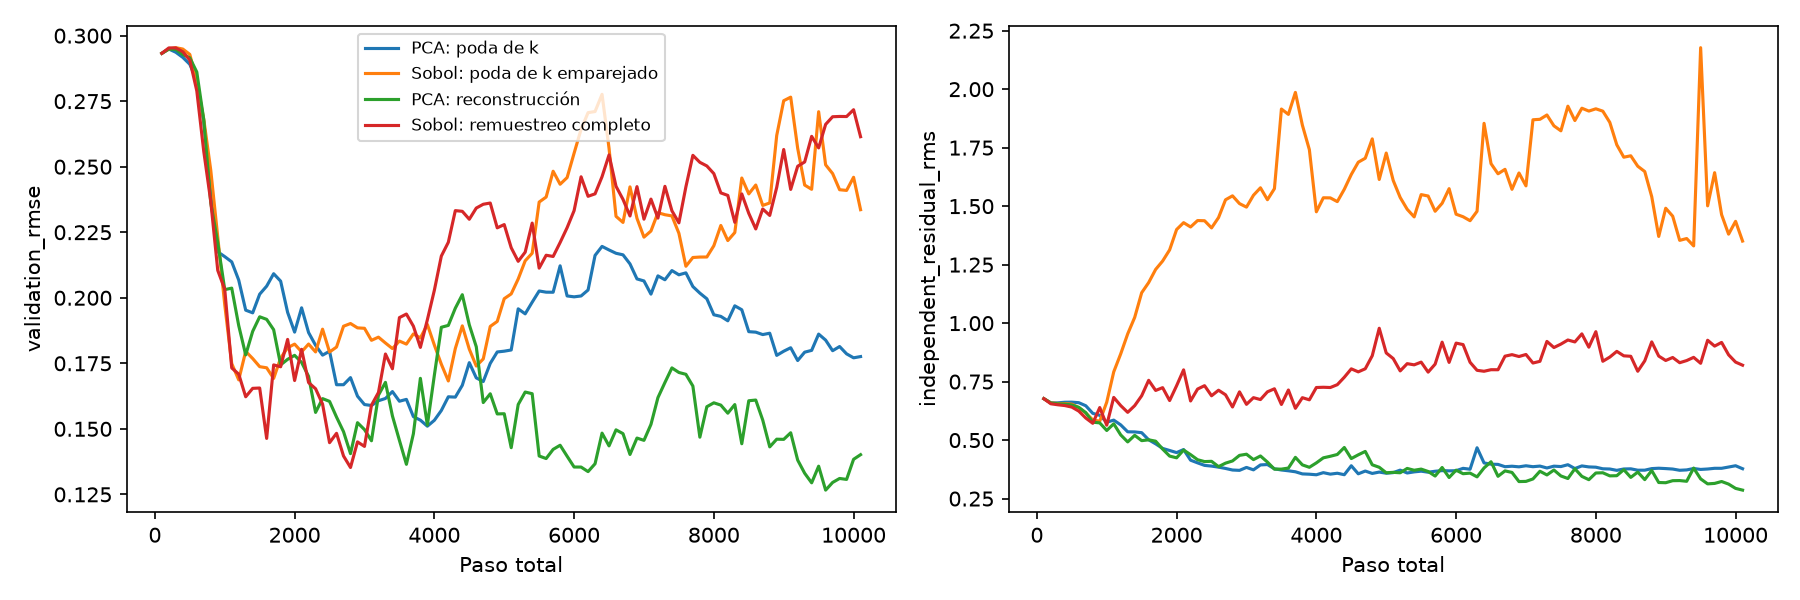

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pde_pruning/pde_only_rank_pruning_10seeds_10k_v1/comparison.png'), format='png', embed=True))


PCA: poda de k: 990/990 podas aceptadas, k entre 2 y 7, media 4.58.

Sobol: poda de k emparejado: 990/990 podas aceptadas, k entre 2 y 7, media 4.58.

El presupuesto terminal está prefijado. DE es dispersión entre semillas; el bootstrap con diez diferencias es exploratorio y no corrige multiplicidad. El residuo se evalúa sobre puntos independientes; IC/BC se comprueban en una malla adicional. Las auditorías reconstruyen ochenta podas, comprueban calendario k común y comienzo idéntico. residence.csv distingue permanencias completas y sobrevivientes censurados. No se afirma aceleración.

Reproducir: `python scripts/run_collocation_pde_pruning.py`. Las corridas completas se reutilizan; manifest.json identifica procedencia. Las figuras están incrustadas como PNG.